# Case study: the summer 2012 central U.S. heat wave

## Purpose

How do the initialization approaches represent the late-June to early-July 2012 central U.S. heat wave, under the prescribed observed SST of the F20TR hindcasts? This notebook does the first steps of the case study: the simulation coverage of the event, the event defined from observations, the regional daily evolution of every member against the observations, and heat metrics of every member. Process diagnostics (soil moisture, surface energy partitioning, ridge evolution, initial adjustment) follow in later notebooks once these results show what differs.

## Design: three questions

| Question | Experiments | Reading |
|---|---|---|
| Q1. Does event-informed initialization improve the event? | HYB_BASE and DA_COUPLED against CLIM_BASE | benefit of the initialized state packages relative to the free-running-reference baseline (CLIM_BASE starts from a free-running climate state with DART-derived perturbations, so it carries no information about 2012) |
| Q2. Do the two initialization approaches differ? | DA_COUPLED against HYB_BASE | joint DART atmosphere-land initialization against the hybrid ERA5 atmosphere with DATM-forced land |
| Q3. What roles do the component states and their consistency play? | DA_ATM (DART atmosphere, reference land) and DA_LND (ERA5 atmosphere, DART land) with the two initialized configurations | component sensitivity; whether the joint result resembles one component experiment or differs from both. It does not by itself separate better component states from better atmosphere-land consistency. |

`PRIMARY` sets the experiments of Q1 and Q2 (the first series figure); all five appear in the second series figure and in the metrics. All are 20-member ensembles (member numbers are labels; the members are not paired across experiments).

**Caveat (2026-11-06):** HYB_BASE and DA_LND started from an ERA5 atmosphere file without the radiative tracers (H2OLNZ, O3, N2OLNZ, CH4LNZ), aerosols and chemistry: they are about 6-7 K too cold over land from day 1. They are drawn dashed and marked "IC defect" (`IC_DEFECT`) until their reruns from the completed initial files (`ensemble_perturbations/complete_era5_initial_states.ipynb`) replace them; Q2 and the DA_LND part of Q3 cannot be answered before then.

## Event definition (from observations only)

Region `REGION` (default central U.S., 35-45N, 105-85W, land), daily-mean 2-m temperature (the archive has ERA5 daily means, not daily maxima, so this is a daily-mean heat event and does not verify station maximum-temperature records). A day is hot when the regional-mean ERA5 temperature exceeds its calendar-day `PERCENTILE` (90th) over `CLIM_YEARS` and +-`HALF_WINDOW` days; an event is at least `MIN_EVENT_DAYS` consecutive hot days. The event window is the observed event with the largest accumulated exceedance from June on, unless `EVENT_WINDOW` is set. The gridpoint version of the same threshold gives the area above threshold.

## Metrics (every member)

On the observed event window: event-mean anomaly, peak anomaly and its date error (peak searched within +-`PEAK_TOLERANCE_DAYS` of the window), days above the threshold and the longest run, accumulated exceedance, mean area fraction above the gridpoint threshold, and event-total precipitation. The model anomaly is taken from the AMIP climatology (`amip`, model mean bias removed) or the observed climatology (`none`), as in notebooks 02-05 (`BIASES`); the threshold is always the observed one minus the observed climatology. These are case-specific measures, not general forecast skill.

## Outputs

`data/hind_lead_eval/heatwave_2012/`: `box_<CONFIG>_<SEASON>_<VAR>.nc` (member fields on the map box), `observed_events.csv`, `coverage.csv`, `heat_metrics.csv` (members) and `heat_metrics_obs.csv`; figures in `figure/hind_lead_eval/heatwave_2012/`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths, experiments, event definition and options. Plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"           # land fraction
AMIP_ROOT = OBSERVATION_ROOT / "E3SMv3"                        # free-running E3SMv3 DECK AMIP runs
WORKFLOW_NAME = "hind_lead_eval"

CONFIGS = ["CLIM_BASE", "HYB_BASE", "DA_COUPLED", "DA_ATM", "DA_LND"]  # metrics order: Q1/Q2, then Q3
PRIMARY = ["CLIM_BASE", "HYB_BASE", "DA_COUPLED"]                      # Q1 and Q2
IC_DEFECT = ["HYB_BASE", "DA_LND"]   # started without radiative tracers; [] once rerun
SEASON = "JJA"                       # the May 2012 starts
N_DAYS = 61                          # simulated days used (lead 1 = start date)
MAX_MEMBERS = None                   # e.g. 4 for a quick test
REQUIRE_ALL_MEMBERS = True

MAP_BOX = dict(lat=(24.5, 50.5), lon=(234.5, 294.5))                       # CONUS, fields kept here
REGION = dict(name="CENTRAL_US", lat=(35.0, 45.0), lon=(255.0, 275.0), mask="land")  # 35-45N, 105-85W
OBS_PERIOD = ("2012-05-16", "2012-07-31")   # covers every start's simulated days
CLIM_YEARS = (2001, 2014)
AMIP_CASES = ("v3.LR.amip_0101", "v3.LR.amip_0151")
PERCENTILE = 0.9
HALF_WINDOW = 7          # days on either side for the calendar-day percentile
MIN_EVENT_DAYS = 3
EVENT_WINDOW = None      # e.g. ("2012-06-27", "2012-07-07"); None: the largest observed event from June on
PEAK_TOLERANCE_DAYS = 7
BIASES = ("amip", "none")
SPREAD = (0.1, 0.9)      # member quantiles shaded in the series

FORCE_COMPUTE = False
SHOW = True
FIGURE_DPI = 200

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.fcst_init_experiment_config import STYLE_MAP, balanced_runs, check_configs, init_dates, readiness
from configs.fcst_init_experiment_config import members as config_members
from configs.output_paths import workflow_output_dirs

check_configs(CONFIGS)
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, "heatwave_2012", output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(data_root=INPUT_DATA_ROOT, land_support_dir=LAND_SUPPORT_DIR)
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")


def save(fig, name):
    path = figure_dir / name
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012


## 4. Read input

Every configuration must be post-processed for the season; the members of each configuration in that season.

In [4]:
status = readiness(CONFIGS, [SEASON], streams=(("atm", "daily"), ("atm", "6hourly")), data_root=INPUT_DATA_ROOT)
RUNS = balanced_runs(status, REQUIRE_ALL_MEMBERS)
inits = list(init_dates([SEASON])[SEASON])
members = {c: (lambda m: m if MAX_MEMBERS is None else m[:MAX_MEMBERS])(config_members(c, SEASON)) for c in CONFIGS}
print(f"[RUNS] {RUNS}\n[STARTS] {[str(i) for i in inits]}\n[MEMBERS] {({c: len(m) for c, m in members.items()})}")

[RUNS] [('CLIM_BASE', 'JJA'), ('DA_ATM', 'JJA'), ('DA_COUPLED', 'JJA'), ('DA_LND', 'JJA'), ('HYB_BASE', 'JJA')]
[STARTS] ['2012-05-16', '2012-05-21', '2012-05-26', '2012-05-31']
[MEMBERS] {'CLIM_BASE': 20, 'HYB_BASE': 20, 'DA_COUPLED': 20, 'DA_ATM': 20, 'DA_LND': 20}


## 5. Observed event

ERA5 daily-mean TREFHT and GPCP precipitation on the map box, both climatologies, the calendar-day thresholds, the observed events and the event window; then the simulation coverage of the window.

In [5]:
from util.fcst_init_data import region_masks
from util.heatwave_case import (climatologies, coverage_table, heat_metrics, observed_box, observed_events,
                                percentile_threshold, region_mean, region_weights)

years = range(CLIM_YEARS[0], CLIM_YEARS[1] + 1)
obs_T = observed_box("TREFHT", *OBS_PERIOD, MAP_BOX, observation_root=OBSERVATION_ROOT)
obs_P = observed_box("PRECT", *OBS_PERIOD, MAP_BOX, observation_root=OBSERVATION_ROOT)
mask = region_masks([REGION], obs_T.lat.values, obs_T.lon.values, land_support_dir=LAND_SUPPORT_DIR).isel(region=0)
w = region_weights(mask)
clim = climatologies("TREFHT", *OBS_PERIOD, years, MAP_BOX, observation_root=OBSERVATION_ROOT, amip_root=AMIP_ROOT,
                     amip_cases=AMIP_CASES, land_support_dir=LAND_SUPPORT_DIR)
thr = percentile_threshold("TREFHT", *OBS_PERIOD, years, MAP_BOX, w, q=PERCENTILE, half_window=HALF_WINDOW,
                           observation_root=OBSERVATION_ROOT)
print(f"[REGION] {REGION['name']}: {int(mask.sum())} land points\n[CLIM] observed: {clim.attrs['clim_obs']}\n"
      f"[CLIM] model: {clim.attrs['clim_amip']}")

times = obs_T.time.values
s_obs = region_mean(obs_T, w)
c_reg = {"none": region_mean(clim.clim_obs, w), "amip": region_mean(clim.clim_amip, w)}
a_obs = s_obs - c_reg["none"]
thr_anom = thr.thr_region - c_reg["none"]                  # regional threshold as an anomaly
thr_anom_grid = thr.thr_grid - clim.clim_obs               # gridpoint threshold as an anomaly
area_obs = region_mean((obs_T > thr.thr_grid).astype("float64"), w)

events = observed_events(s_obs, thr.thr_region, a_obs, MIN_EVENT_DAYS)
events.to_csv(data_dir / "observed_events.csv", index=False)
display(events)
if EVENT_WINDOW is None:
    cand = events[pd.to_datetime(events.onset) >= pd.Timestamp("2012-06-01")]
    best = cand.loc[cand.accumulated_exceedance.idxmax()]
    window, obs_peak = (str(best.onset), str(best.end)), str(best.peak_date)
else:
    window = EVENT_WINDOW
    seg = a_obs.sel(time=slice(*window))
    obs_peak = str(pd.Timestamp(seg.time.values[int(np.argmax(seg.values))]).date())
print(f"[EVENT] window {window[0]} to {window[1]}, observed peak {obs_peak}")
print(f"[CLIM] AMIP minus observed climatology over the region, window mean: "
      f"{float((c_reg['amip'] - c_reg['none']).sel(time=slice(*window)).mean()):+.2f} K")

obs_metrics = heat_metrics(a_obs.values, times, thr_anom.values, area_obs.values, window, obs_peak, PEAK_TOLERANCE_DAYS)
obs_metrics["event_precip_mm"] = float(region_mean(obs_P, w).sel(time=slice(*window)).sum())
pd.DataFrame([obs_metrics]).to_csv(data_dir / "heat_metrics_obs.csv", index=False)
cov = coverage_table(inits, N_DAYS, window)
cov.to_csv(data_dir / "coverage.csv", index=False)
display(pd.DataFrame([obs_metrics]).T.rename(columns={0: "observed"}), cov)

Warning 3: Cannot find header.dxf (GDAL_DATA is not defined)
ERROR 1: PROJ: proj_create_from_database: Cannot find proj.db


[REGION] CENTRAL_US: 200 land points
[CLIM] observed: ERA5 1x1 daily: monthly means of the daily series
[CLIM] model: E3SMv3 AMIP monthly (v3.LR.amip_0101, v3.LR.amip_0151; cmip_ts (time bounds))


,onset,end,days,peak_date,peak_anomaly,mean_anomaly,accumulated_exceedance
0,2012-05-26,2012-05-28,3,2012-05-27,5.974867,4.883940,3.888984
1,2012-06-27,2012-07-07,11,2012-07-04,6.023516,5.132508,21.989881
2,2012-07-16,2012-07-19,4,2012-07-18,4.131196,3.942649,2.141503
3,2012-07-22,2012-07-25,4,2012-07-23,5.399203,4.955266,5.215095


[EVENT] window 2012-06-27 to 2012-07-07, observed peak 2012-07-04
[CLIM] AMIP minus observed climatology over the region, window mean: +1.12 K


,observed
event_mean_anomaly,5.132508
peak_anomaly,6.023516
peak_date_error_days,0.000000
exceedance_days,11.000000
longest_run_days,11.000000
accumulated_exceedance,21.989881
area_fraction_mean,0.707566
window_days_covered,11.000000
event_precip_mm,10.797355


,init,last_day,lead_at_onset,lead_at_end,window_covered
0,2012-05-16,2012-07-15,43,53,full
1,2012-05-21,2012-07-20,38,48,full
2,2012-05-26,2012-07-25,33,43,full
3,2012-05-31,2012-07-30,28,38,full


## 6. Model fields

Daily TREFHT (mean of the four 6-hour means) and PRECT of every member on the map box (cached; reused unless `FORCE_COMPUTE`), put on calendar days.

In [6]:
from util.heatwave_case import calendar, model_box

fields = {}
for c in CONFIGS:
    for v in ("TREFHT", "PRECT"):
        fields[c, v] = model_box(c, SEASON, v, members[c], MAP_BOX, n_days=N_DAYS,
                                 cache=data_dir / f"box_{c}_{SEASON}_{v}.nc", force=FORCE_COMPUTE, **ROOTS)
        print(f"[MODEL] {c} {v}: {dict(fields[c, v].sizes)}")
if not np.allclose(fields[CONFIGS[0], "TREFHT"].lat, obs_T.lat) or not np.allclose(fields[CONFIGS[0], "TREFHT"].lon, obs_T.lon):
    raise ValueError("model and observation grids differ on the map box")


def on_calendar(da, init):
    """(member, time, lat, lon) of one start on its calendar days, within OBS_PERIOD."""
    x = da.sel(init=np.datetime64(init, "ns")).drop_vars("init", errors="ignore")
    x = x.assign_coords(lead=calendar(init, x.lead.values).astype("datetime64[ns]")).rename(lead="time")
    return x.sel(time=slice(*OBS_PERIOD))

[MODEL] CLIM_BASE TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] CLIM_BASE PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] HYB_BASE TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] HYB_BASE PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_COUPLED TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_COUPLED PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_ATM TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_ATM PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_LND TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_LND PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


## 7. Regional series and metrics

Regional-mean anomalies of every member (both bias treatments), area fraction above the gridpoint threshold, precipitation accumulated from the start, and the metrics on the event window.

In [7]:
series, precip, rows = {}, {}, []
for c in CONFIGS:
    for init in inits:
        T = on_calendar(fields[c, "TREFHT"], init)
        P = on_calendar(fields[c, "PRECT"], init)
        t = T.time.values
        precip[c, init] = region_mean(P, w).cumsum("time")
        p_event = region_mean(P, w).sel(time=slice(*window)).sum("time")
        for b in BIASES:
            clim_grid = (clim.clim_amip if b == "amip" else clim.clim_obs).sel(time=t)
            anom_grid = T - clim_grid
            series[b, c, init] = region_mean(anom_grid, w)
            area = region_mean((anom_grid > thr_anom_grid.sel(time=t)).astype("float64"), w)
            th = thr_anom.sel(time=t).values
            for k, m in enumerate(T.member.values):
                r = heat_metrics(series[b, c, init].isel(member=k).values, t, th, area.isel(member=k).values,
                                 window, obs_peak, PEAK_TOLERANCE_DAYS)
                rows.append(dict(bias=b, config=c, init=str(init), member=str(m), **r,
                                 event_precip_mm=float(p_event.isel(member=k))))
metrics = pd.DataFrame(rows)
metrics.to_csv(data_dir / "heat_metrics.csv", index=False)
print(f"[WRITE] {data_dir / 'heat_metrics.csv'}")
summary = (metrics.groupby(["bias", "config"]).median(numeric_only=True)
           .reindex(CONFIGS, level="config"))
display(summary.round(2))
display(pd.DataFrame([obs_metrics], index=["OBS"]).round(2))

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/heat_metrics.csv


event_mean_anomaly  peak_anomaly  peak_date_error_days  \
bias config                                                               
amip CLIM_BASE                 0.47          3.21                  -2.5   
     HYB_BASE                 -1.57          1.25                   2.5   
     DA_COUPLED                0.93          4.19                  -3.5   
     DA_ATM                    0.95          4.66                  -6.0   
     DA_LND                   -1.80          1.25                   5.0   
none CLIM_BASE                 1.59          4.55                   1.0   
     HYB_BASE                 -0.45          2.83                   4.5   
     DA_COUPLED                2.05          5.23                   0.0   
     DA_ATM                    2.07          5.79                  -3.0   
     DA_LND                   -0.68          2.75                   7.0   

                 exceedance_days  longest_run_days  accumulated_exceedance  \
bias config                                                                  
amip CLIM_BASE               0.0               0.0                    0.00   
     HYB_BASE                0.0               0.0                    0.00   
     DA_COUPLED              0.0               0.0                    0.00   
     DA_ATM                  1.5               1.0                    0.82   
     DA_LND                  0.0               0.0                    0.00   
none CLIM_BASE               2.0               2.0                    0.94   
     HYB_BASE                0.0               0.0                    0.00   
     DA_COUPLED              2.0               2.0                    1.46   
     DA_ATM                  3.0               3.0                    3.05   
     DA_LND                  0.0               0.0                    0.00   

                 area_fraction_mean  window_days_covered  event_precip_mm  
bias config                                                                
amip CLIM_BASE                 0.07                 11.0            35.82  
     HYB_BASE                  0.01                 11.0            24.94  
     DA_COUPLED                0.10                 11.0            35.97  
     DA_ATM                    0.14                 11.0            33.52  
     DA_LND                    0.00                 11.0            26.03  
none CLIM_BASE                 0.16                 11.0            35.82  
     HYB_BASE                  0.04                 11.0            24.94  
     DA_COUPLED                0.20                 11.0            35.97  
     DA_ATM                    0.25                 11.0            33.52  
     DA_LND                    0.03                 11.0            26.03

,event_mean_anomaly,peak_anomaly,peak_date_error_days,exceedance_days,longest_run_days,accumulated_exceedance,area_fraction_mean,window_days_covered,event_precip_mm
OBS,5.13,6.02,0,11,11,21.99,0.71,11,10.8


## 8. Plot and show

Coverage and observed event; regional series per start (Q1/Q2 experiments, then all five); member metrics; event-window mean anomaly maps.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_coverage.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_series_primary_amip.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_series_all_amip.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_metrics_amip.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_maps_amip.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_series_primary_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_series_all_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_metrics_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_maps_none.png


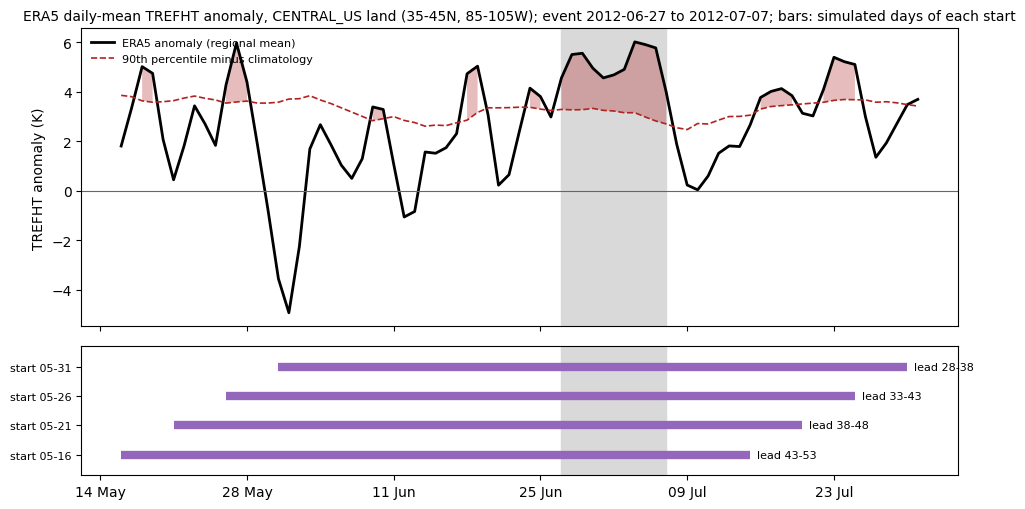

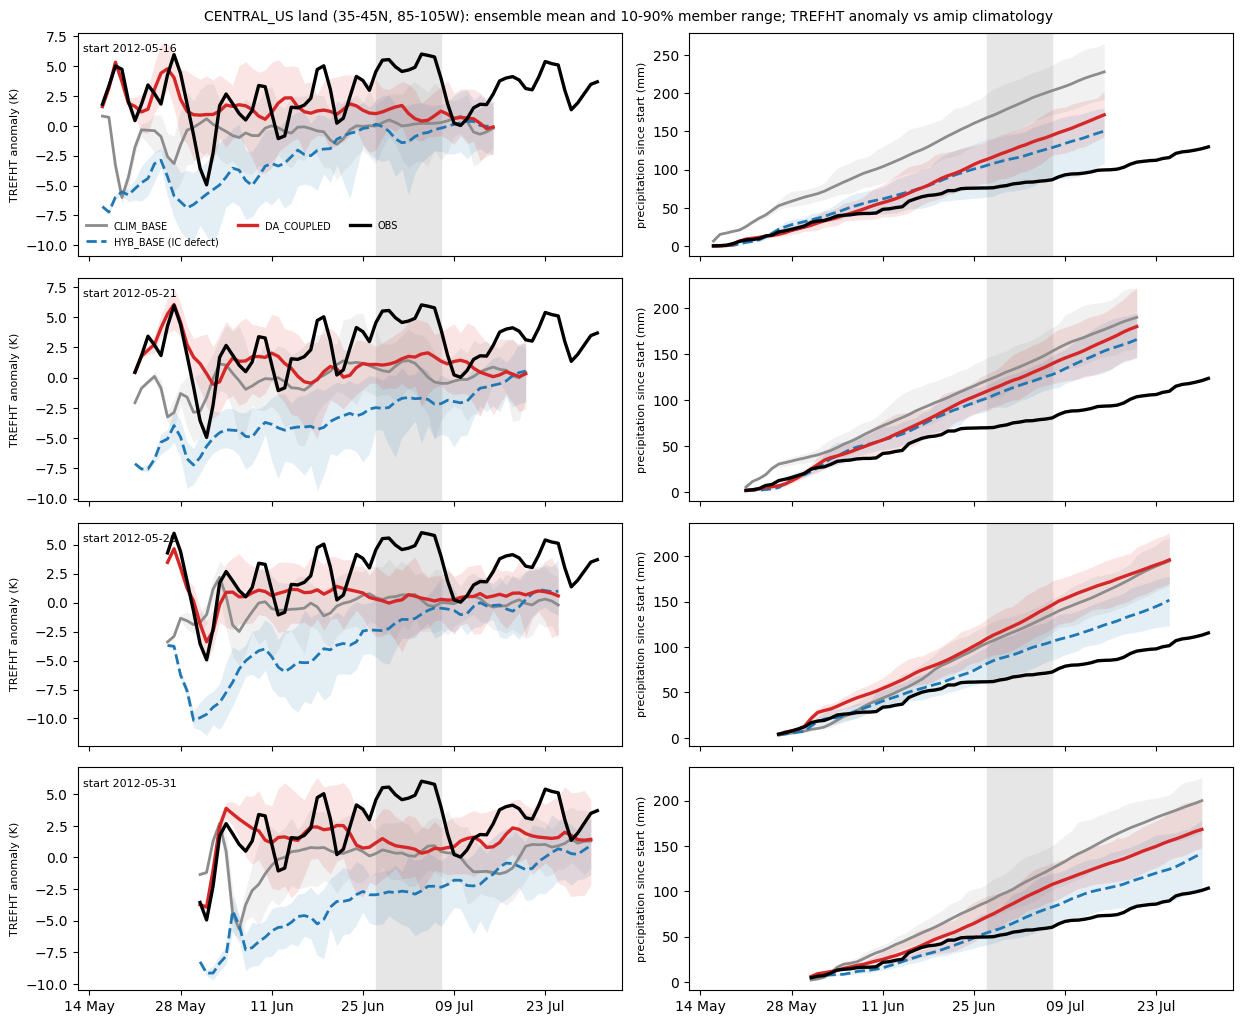

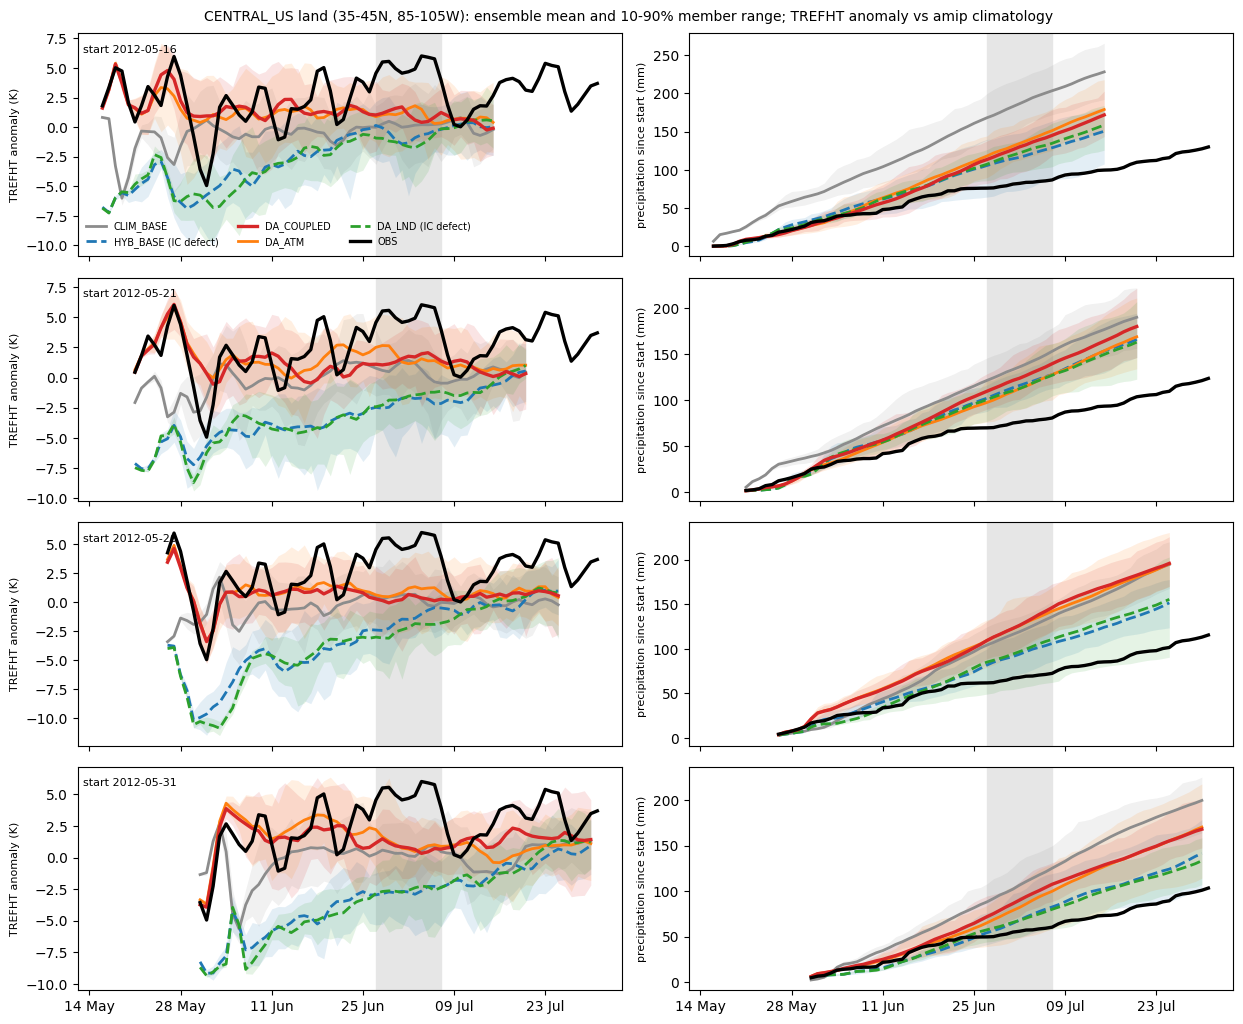

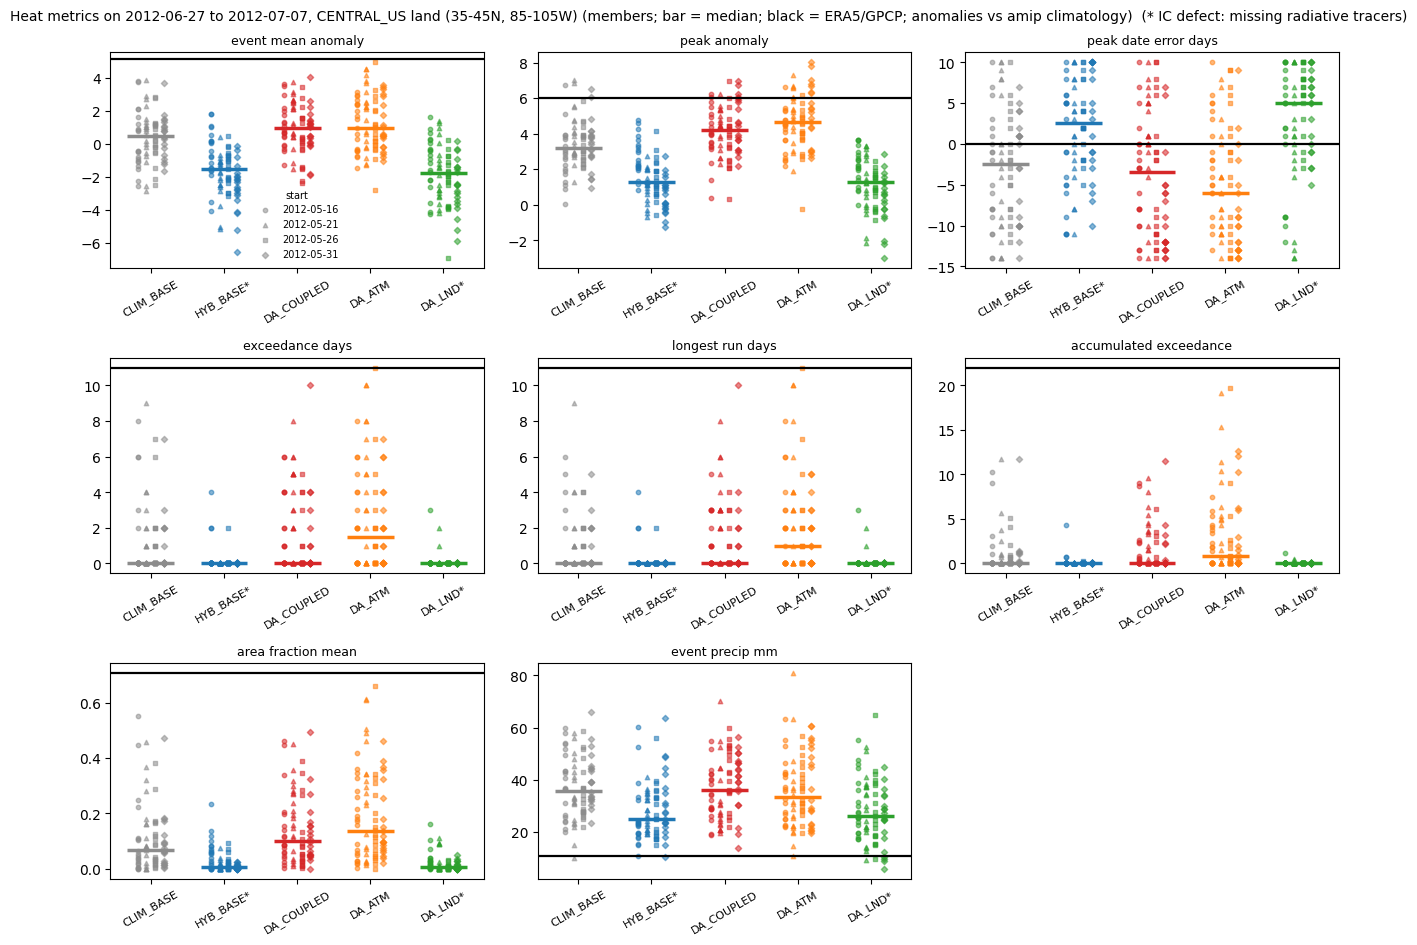

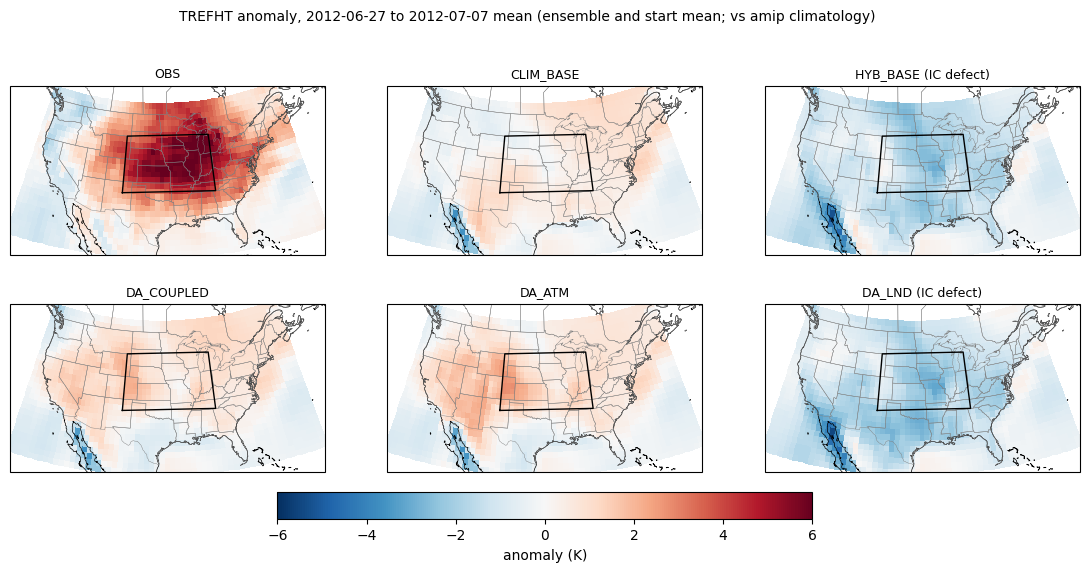

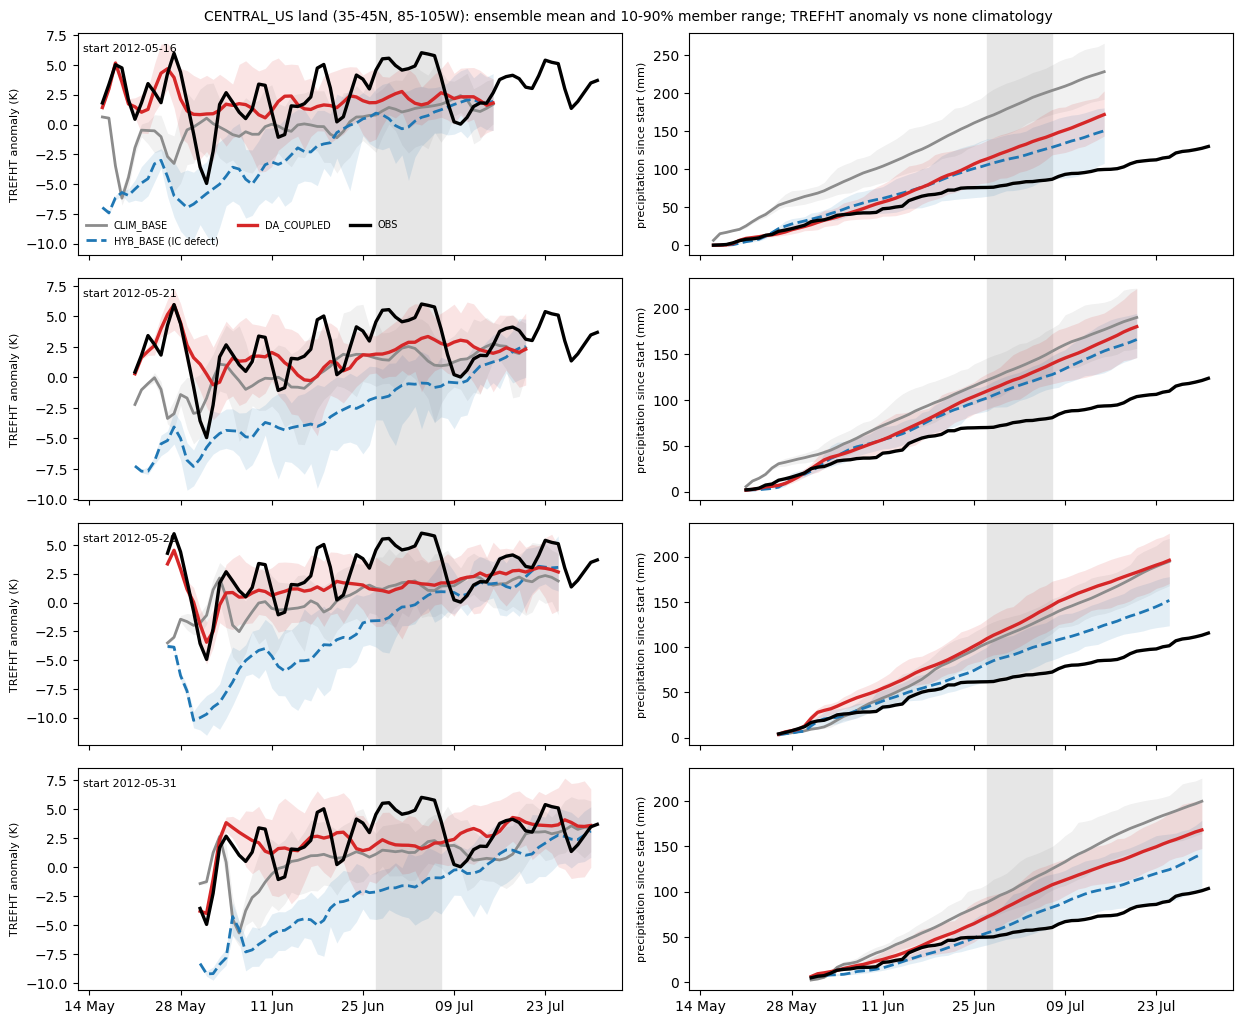

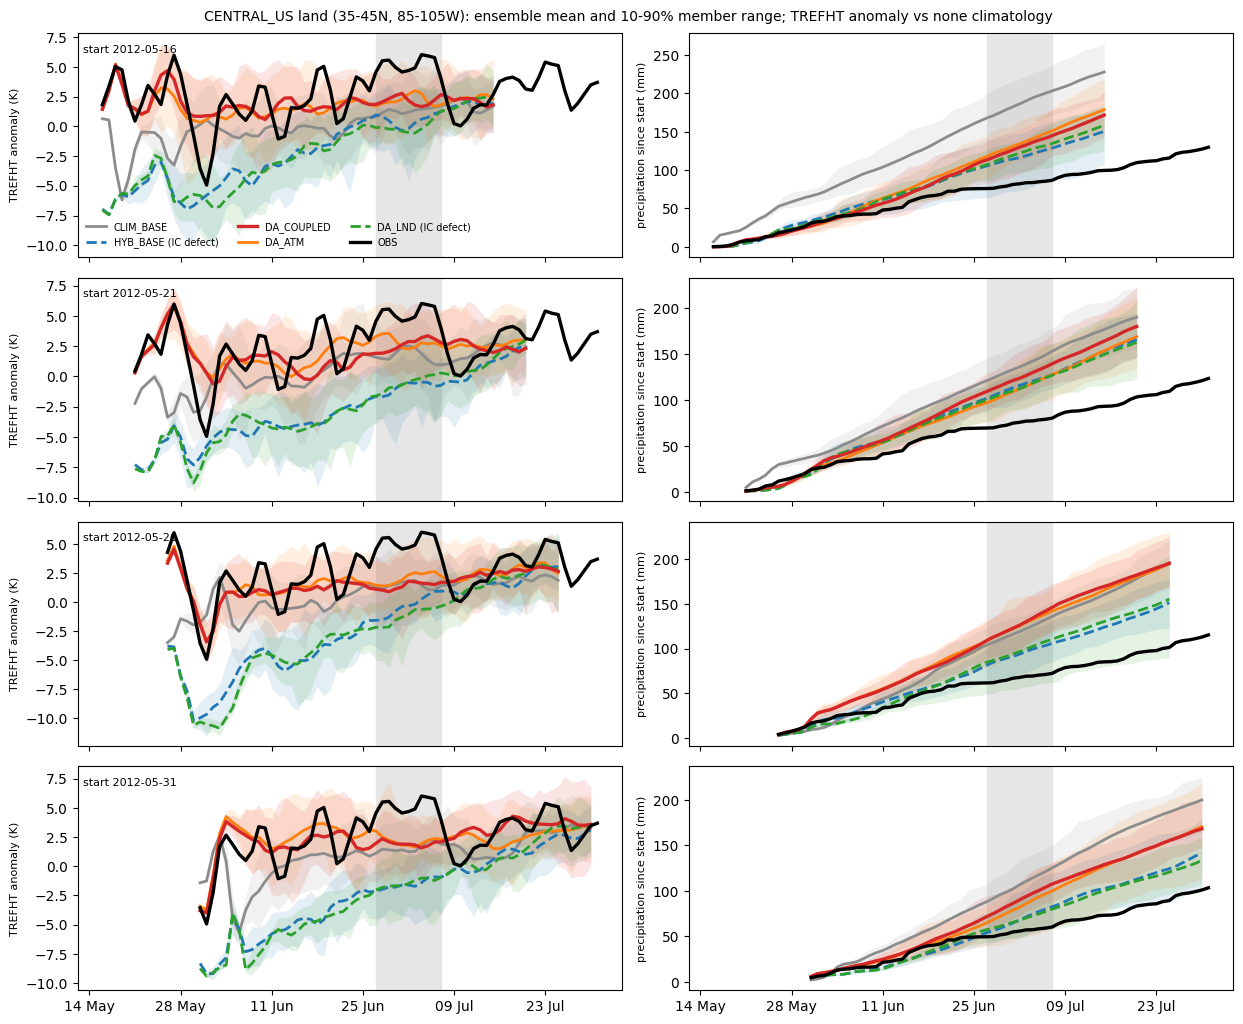

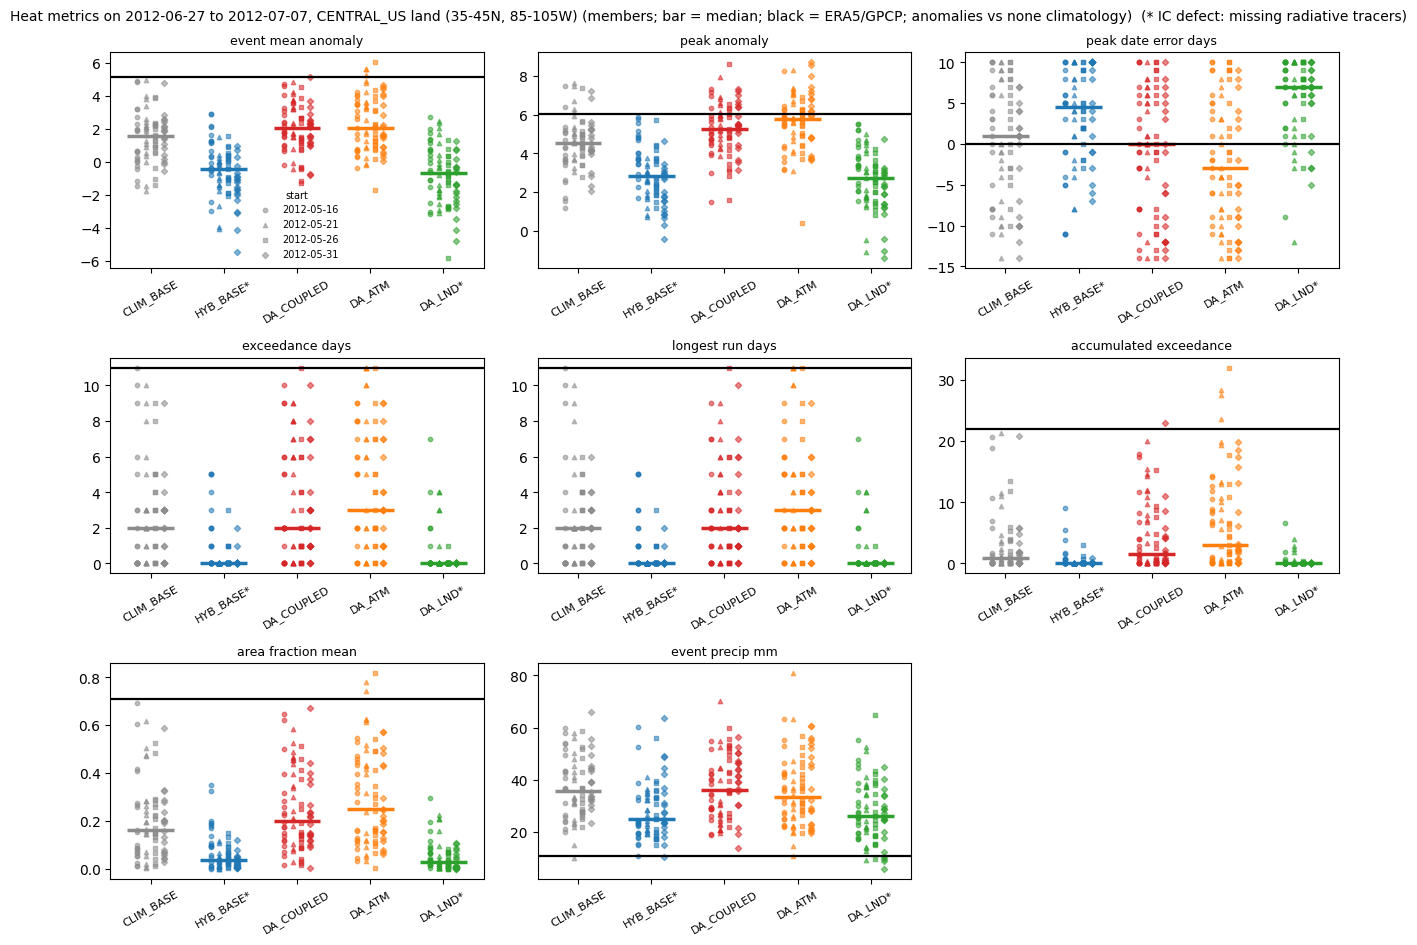

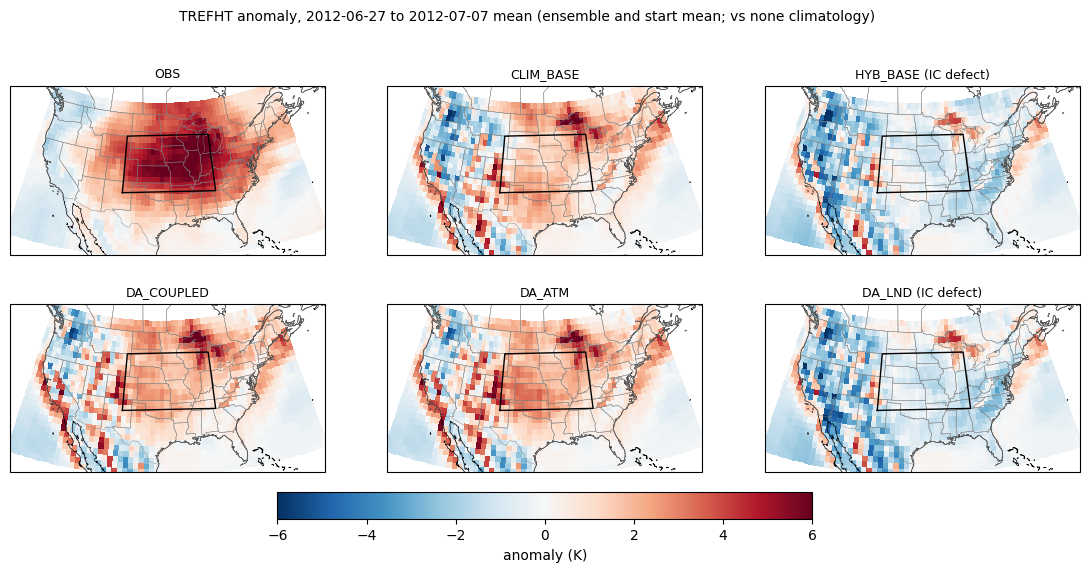

In [8]:
from util.heatwave_case import plot_coverage, plot_maps, plot_metrics, plot_series

label = f"{REGION['name']} land ({REGION['lat'][0]:g}-{REGION['lat'][1]:g}N, {360 - REGION['lon'][1]:g}-{360 - REGION['lon'][0]:g}W)"
save(plot_coverage(cov, window, a_obs, thr_anom,
                   title=f"ERA5 daily-mean TREFHT anomaly, {label}; event {window[0]} to {window[1]}; "
                         f"bars: simulated days of each start"), "heatwave_coverage.png")

obs_cum = {init: region_mean(obs_P, w).sel(time=slice(np.datetime64(init, 'ns'), None)).cumsum("time") for init in inits}
ylabels = {"TREFHT": "TREFHT anomaly (K)", "PRECT": "precipitation since start (mm)"}
METRICS = ["event_mean_anomaly", "peak_anomaly", "peak_date_error_days", "exceedance_days", "longest_run_days",
           "accumulated_exceedance", "area_fraction_mean", "event_precip_mm"]
for b in BIASES:
    for tag, cfgs in (("primary", PRIMARY), ("all", CONFIGS)):
        panels = {"TREFHT": {i: {c: series[b, c, i] for c in cfgs} for i in inits},
                  "PRECT": {i: {c: precip[c, i] for c in cfgs} for i in inits}}
        save(plot_series(panels, {"TREFHT": a_obs, "PRECT": obs_cum}, window, STYLE_MAP, IC_DEFECT, ylabels=ylabels,
                         spread=SPREAD,
                         title=f"{label}: ensemble mean and {int(SPREAD[0] * 100)}-{int(SPREAD[1] * 100)}% member range; "
                               f"TREFHT anomaly vs {b} climatology"),
             f"heatwave_series_{tag}_{b}.png")
    save(plot_metrics(metrics[metrics.bias == b], obs_metrics, METRICS, CONFIGS, STYLE_MAP, IC_DEFECT,
                      title=f"Heat metrics on {window[0]} to {window[1]}, {label} (members; bar = median; "
                            f"black = ERA5/GPCP; anomalies vs {b} climatology)"),
         f"heatwave_metrics_{b}.png")
    obs_map = (obs_T - clim.clim_obs).sel(time=slice(*window)).mean("time")
    model_maps = {}
    for c in CONFIGS:
        x = [(on_calendar(fields[c, "TREFHT"], i) - (clim.clim_amip if b == "amip" else clim.clim_obs))
             .sel(time=slice(*window)).mean(("time", "member")) for i in inits]
        model_maps[c] = xr.concat(x, "init").mean("init")
    save(plot_maps(obs_map, model_maps, REGION, IC_DEFECT,
                   title=f"TREFHT anomaly, {window[0]} to {window[1]} mean (ensemble and start mean; vs {b} climatology)"),
         f"heatwave_maps_{b}.png")